Training data: (27455, 784)
Testing data: (7172, 784)
Number of classes: 24


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 512)                 │         401,920 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 24)                  │           6,168 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 539,416 (2.06 MB)

 Trainable params: 539,416 (2.06 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
194/194 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.2861 - loss: 2.3152 - val_accuracy: 0.4956 - val_loss: 1.6349
Epoch 2/15
194/194 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.5359 - loss: 1.4166 - val_accuracy: 0.6956 - val_loss: 0.9803
Epoch 3/15
194/194 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.6611 - loss: 1.0226 - val_accuracy: 0.7975 - val_loss: 0.6501
Epoch 4/15
194/194 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.7454 - loss: 0.7599 - val_accuracy: 0.7972 - val_loss: 0.6097
Epoch 5/15
194/194 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.7915 - loss: 0.6191 - val_accuracy: 0.8106 - val_loss: 0.5311
Epoch 6/15
194/194 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.8263 - loss: 0.5145 - val_accuracy: 0.8267 - val_loss: 0.4751
Epoch 7/15
194/194 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.8583 - loss: 0.4235 - val_accuracy: 0.9268 - val_loss: 0.2482
Epoch 8/15
194/194 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.8897 - loss: 0.3331 - val_accu

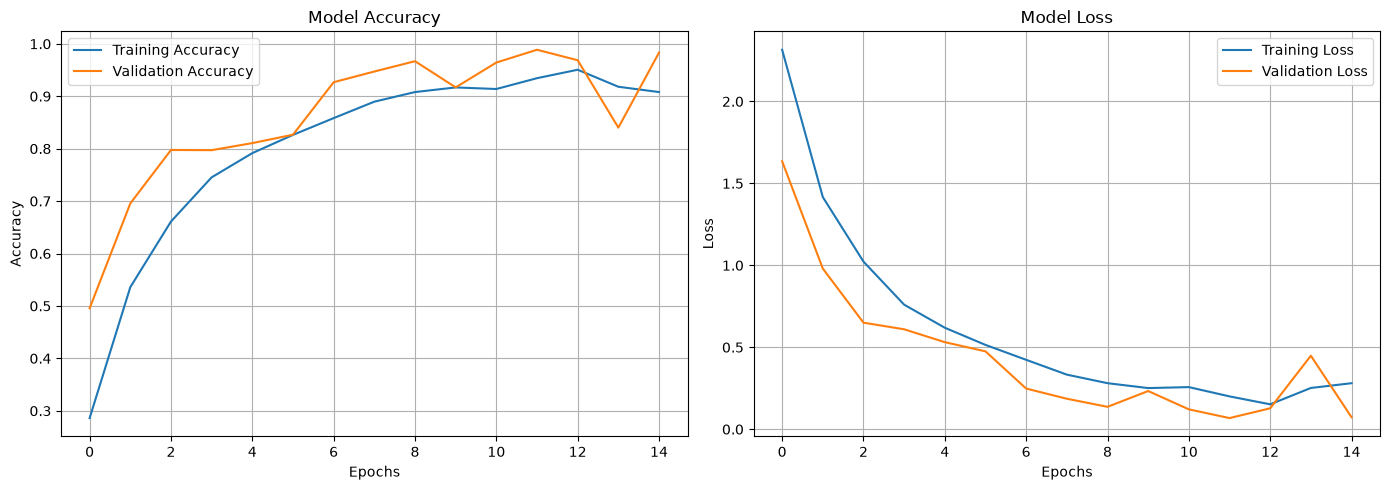

Training Accuracy: 90.8 %
Testing Accuracy: 78.72 %
Testing Loss: 0.8067
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


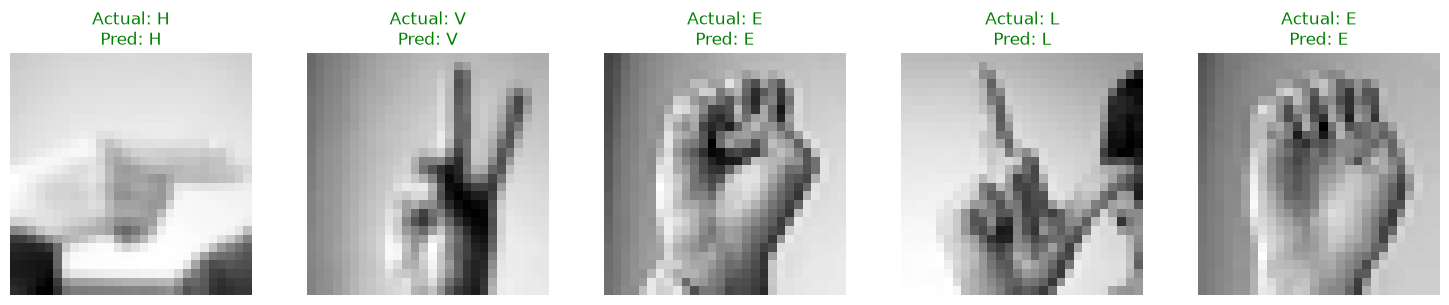

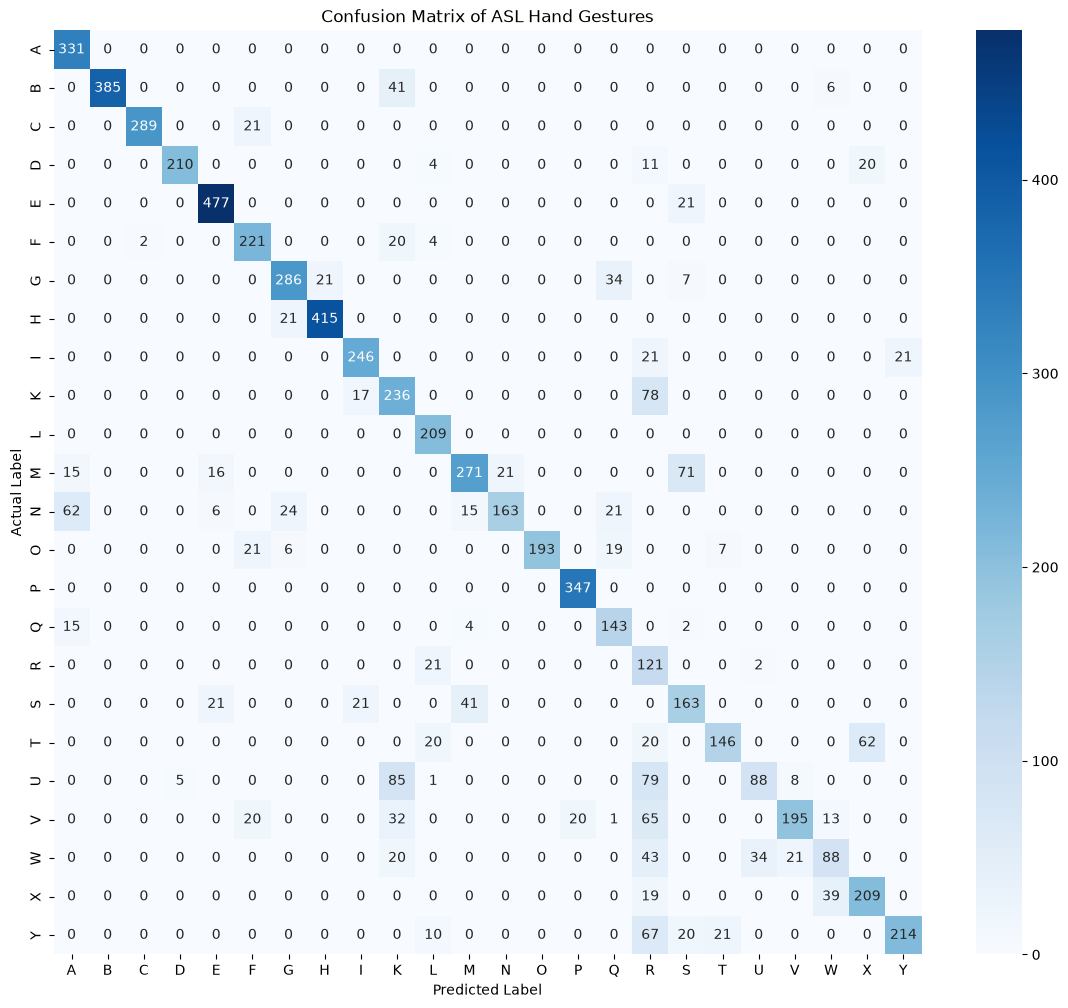

In [1]:

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix

# Load datasets
train_df = pd.read_csv('sign_mnist_train.csv')
test_df = pd.read_csv('sign_mnist_test.csv')

# Handle missing values
train_df = train_df.fillna(0)
test_df = test_df.fillna(0)

# Separate features and labels
y_train_raw = train_df['label'].values
X_train = train_df.drop('label', axis=1).values

y_test_raw = test_df['label'].values
X_test = test_df.drop('label', axis=1).values

# Normalize pixel values
X_train = X_train / 255.0
X_test = X_test / 255.0

# Map labels to consecutive indices (0-23)
label_map = {}
new_idx = 0

for label in sorted(np.unique(y_train_raw)):
    label_map[label] = new_idx
    new_idx += 1

y_train_mapped = np.array([label_map[x] for x in y_train_raw])
y_test_mapped = np.array([label_map[x] for x in y_test_raw])

# Convert labels into one-hot encoding
num_classes = 24
y_train = to_categorical(y_train_mapped, num_classes)
y_test = to_categorical(y_test_mapped, num_classes)

# Alphabet labels (excluding J and Z)
alphabet = [chr(i + 65) for i in range(26)
            if chr(i + 65) not in ['J', 'Z']]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Number of classes:", num_classes)

# Build Feedforward Neural Network
model = Sequential([
    Input(shape=(784,)),
    Dense(512, activation='relu'),
    Dropout(0.2),
    Dense(256, activation='relu'),
    Dropout(0.2),
    Dense(num_classes, activation='softmax')
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# Train the model
history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=15,
    batch_size=128,
    verbose=1
)

# Display training and validation accuracy and loss
plt.figure(figsize=(14, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Evaluate the model on test data
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)

print("Training Accuracy:",
      round(history.history['accuracy'][-1] * 100, 2), "%")
print("Testing Accuracy:", round(test_acc * 100, 2), "%")
print("Testing Loss:", round(test_loss, 4))

# Get predictions
y_pred = np.argmax(model.predict(X_test), axis=1)
y_true = np.argmax(y_test, axis=1)

# Display five test images with actual and predicted labels
indices = np.random.choice(len(X_test), 5, replace=False)

plt.figure(figsize=(15, 3))

for idx, i in enumerate(indices):
    img = X_test[i].reshape(28, 28)

    actual_letter = alphabet[y_true[i]]
    pred_letter = alphabet[y_pred[i]]

    plt.subplot(1, 5, idx + 1)
    plt.imshow(img, cmap='gray')

    color = 'green' if actual_letter == pred_letter else 'red'
    plt.title(f"Actual: {actual_letter}\nPred: {pred_letter}",
              color=color)
    plt.axis('off')

plt.tight_layout()
plt.show()

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(14, 12))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=alphabet,
    yticklabels=alphabet
)

plt.title('Confusion Matrix of ASL Hand Gestures')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()
